# Augment rare cell types

A reference with few cells of some types trains a model that under-calls them.
`augment_data()` balances the classes: types below `norm_number` cells get simulated
cells, and with `prune=True` larger types are down-sampled. The simulated cells draw
molecules from the pooled counts of their type. This tutorial follows the R article
[How to augment data using viewmastR](https://furlan-lab.github.io/viewmastR/articles/Augment.html).

| Role | Dataset |
|---|---|
| Reference | healthy bone marrow atlas (Granja et al. 2019), fine labels `SFClassification` (21 types; T-cell subsets have 400 cells each) |
| Query | T-cell-depleted bone marrow, multiome RNA, both replicates, all 11,744 cells Cell Ranger called (Persad et al. 2023, Zenodo 6383269) |

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import viewmastr as vm
import tutorial_data as td

sc.set_figure_params(dpi=80, frameon=False)
ref = td.greenleaf_reference()
col = "SFClassification"
print(ref.obs[col].value_counts().to_string())

SFClassification
11_CD14.Mono      6021
21_NK             2143
05_CMP.LMPP       2094
07_GMP            2060
01_HSC            2000
02_Early.Eryth    2000
03_Late.Eryth     2000
04_Early.Baso     2000
06_CLP            2000
08_GMP.Neut       2000
09_pDC            2000
10_cDC            2000
12_CD16.Mono      2000
15_Plasma         2000
13_Pre.B          1000
14_B              1000
16_CD8.N           400
17_CD4.N           400
18_CD4.M           400
19_CD8.EM          400
20_CD8.CM          400


## Hold out real cells for an honest test

Keep 20 % of the real cells of every type aside. Both models below train on the other
80 %; only the second one is augmented. The held-out cells are never simulated.

In [2]:
rng = np.random.default_rng(0)
test = np.zeros(ref.n_obs, dtype=bool)
for t, idx in ref.obs.groupby(col, observed=True).indices.items():
    test[rng.choice(idx, len(idx) // 5, replace=False)] = True
train, held = ref[~test].copy(), ref[test].copy()

## Augment to 1,500 cells per type

Types below 1,500 cells get simulated cells; with `prune=True` larger types lose cells.

In [3]:
aug = vm.augment_data(train, col, norm_number=1500, prune=True, seed=1)
print(pd.DataFrame({"before": train.obs[col].value_counts(), "after": aug.obs[col].value_counts()}).to_string())

                  before  after
SFClassification               
01_HSC              1600   1500
02_Early.Eryth      1600   1500
03_Late.Eryth       1600   1500
04_Early.Baso       1600   1500
05_CMP.LMPP         1676   1500
06_CLP              1600   1500
07_GMP              1648   1500
08_GMP.Neut         1600   1500
09_pDC              1600   1500
10_cDC              1600   1500
11_CD14.Mono        4817   1500
12_CD16.Mono        1600   1500
13_Pre.B             800   1500
14_B                 800   1500
15_Plasma           1600   1500
16_CD8.N             320   1500
17_CD4.N             320   1500
18_CD4.M             320   1500
19_CD8.EM            320   1500
20_CD8.CM            320   1500
21_NK               1715   1500


The simulated cells should sit with the real cells of their type in an embedding.

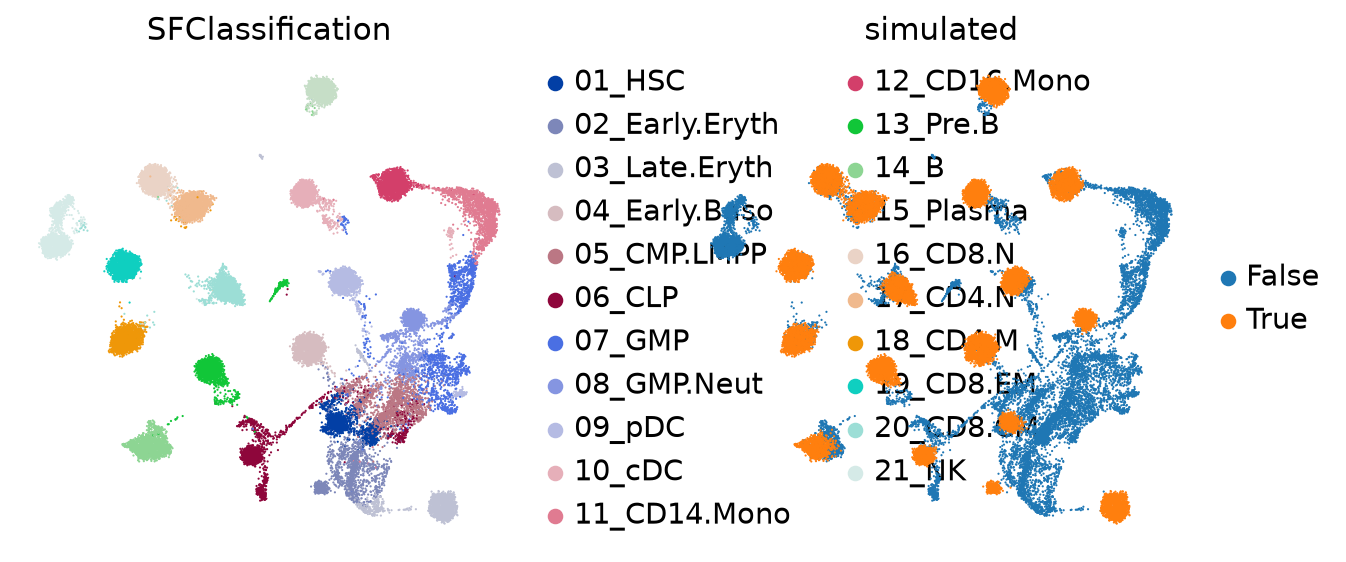

In [4]:
a = aug.copy()
a.obs["simulated"] = a.obs_names.str.startswith("stimcell_").astype(str)
sc.pp.normalize_total(a, target_sum=1e4)
sc.pp.log1p(a)
sc.pp.highly_variable_genes(a, n_top_genes=3000)
sc.pp.pca(a, n_comps=50, mask_var="highly_variable")
sc.pp.neighbors(a, n_pcs=40)
sc.tl.umap(a)
sc.pl.umap(a, color=[col, "simulated"], ncols=2)

## Does augmentation help the rare types?

Train one model on the original training cells and one on the augmented cells, then score
both on the held-out real cells. Recall = share of a type's held-out cells that get the
right label.

                  original  augmented
SFClassification                     
01_HSC               0.965      0.972
02_Early.Eryth       0.952      0.958
03_Late.Eryth        0.978      0.972
04_Early.Baso        1.000      1.000
05_CMP.LMPP          0.914      0.840
06_CLP               0.958      0.955
07_GMP               0.886      0.886
08_GMP.Neut          0.948      0.968
09_pDC               0.990      0.992
10_cDC               0.992      0.998
11_CD14.Mono         0.983      0.968
12_CD16.Mono         0.988      0.992
13_Pre.B             0.975      0.975
14_B                 0.985      0.985
15_Plasma            1.000      1.000
16_CD8.N             0.962      0.938
17_CD4.N             0.900      0.888
18_CD4.M             0.838      0.838
19_CD8.EM            0.962      0.962
20_CD8.CM            0.625      0.662
21_NK                0.993      0.991


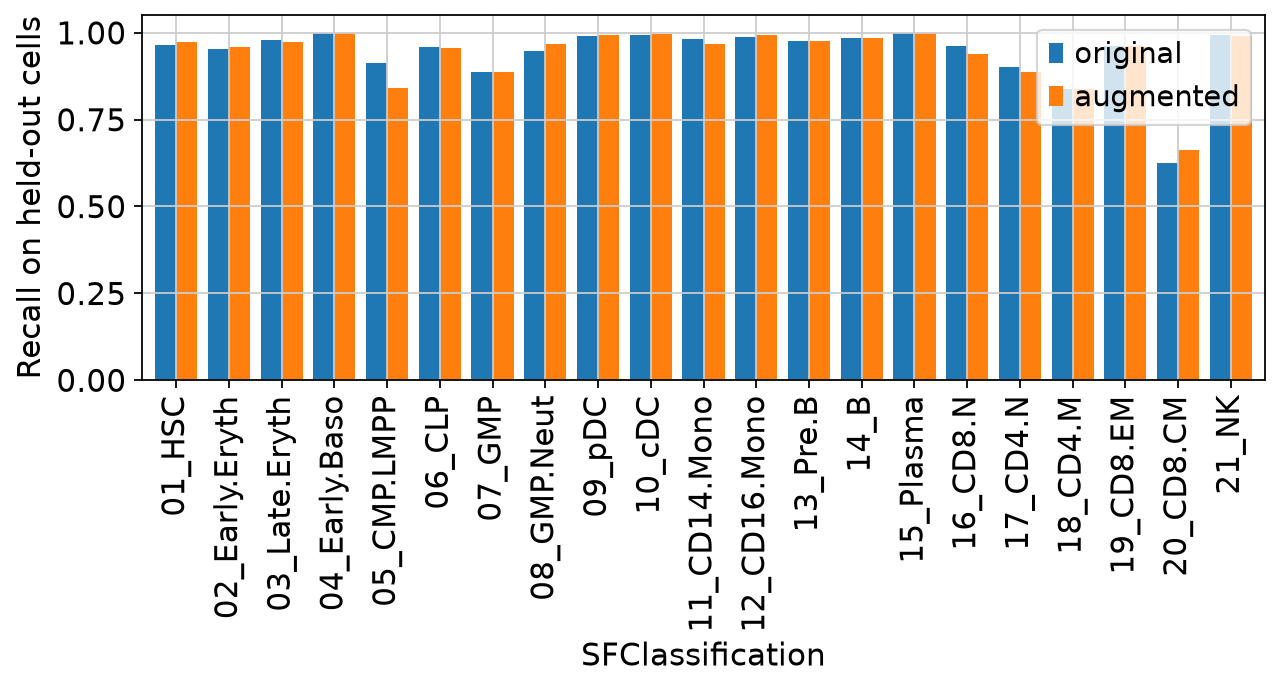

In [5]:
for a_ in (train, aug, held):
    vm.calculate_feature_dispersion(a_)
    vm.select_features(a_, top_n=10_000, logmean_ul=-1, logmean_ll=-8)
vgq = set(vm.get_selected_features(held))
recall = {}
for name, r in (("original", train), ("augmented", aug)):
    vg = [g for g in vm.get_selected_features(r) if g in vgq]
    vm.viewmastR(held, r, col, selected_features=vg, query_celldata_col=f"pred_{name}", seed=1, verbose=False)
    hit = held.obs[f"pred_{name}"].astype(str) == held.obs[col].astype(str)
    recall[name] = hit.groupby(held.obs[col], observed=True).mean()
recall = pd.DataFrame(recall)
print(recall.round(3).to_string())
recall.plot.bar(figsize=(9, 3), width=0.8)
plt.ylabel("Recall on held-out cells")
plt.show()

## Label a query with the augmented reference

(11744, 36601)


viewmastR: 3460 features, 21 classes, 25200 train / 6300 test cells


[epoch 1 | train accuracy 85.948% | validation accuracy 94.714%]


[epoch 2 | train accuracy 95.937% | validation accuracy 95.698%]


[epoch 3 | train accuracy 96.603% | validation accuracy 95.952%]


[epoch 4 | train accuracy 97.060% | validation accuracy 96.111%]


[epoch 5 | train accuracy 97.425% | validation accuracy 96.095%]


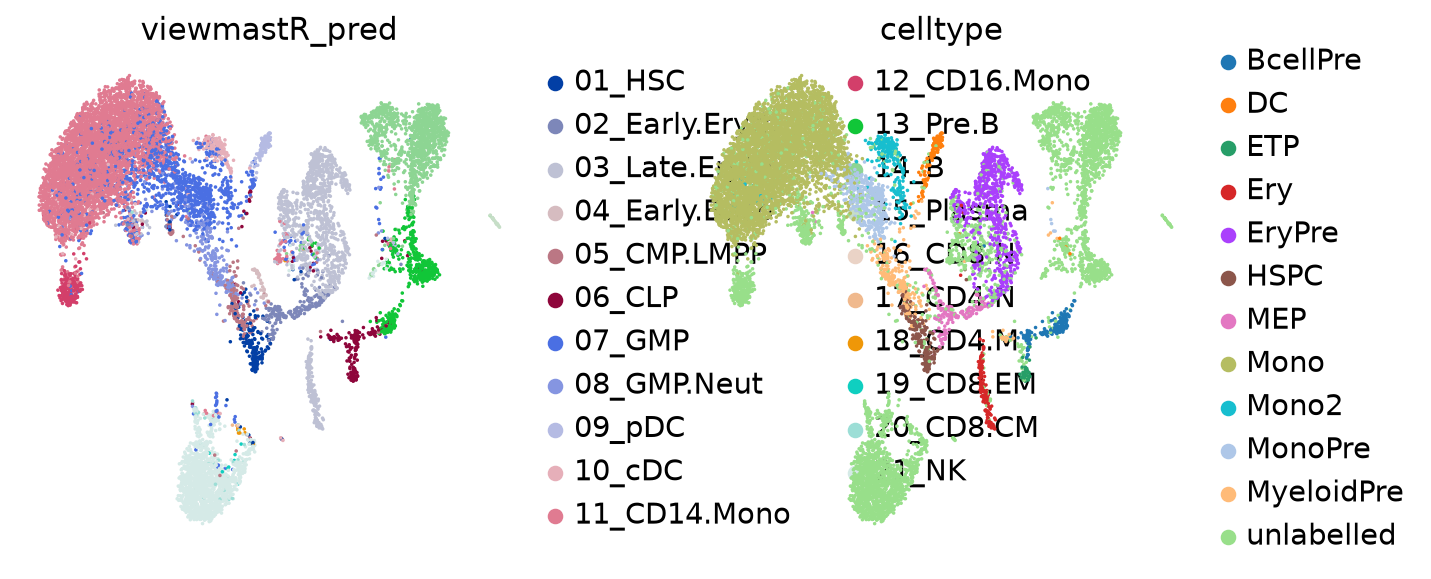

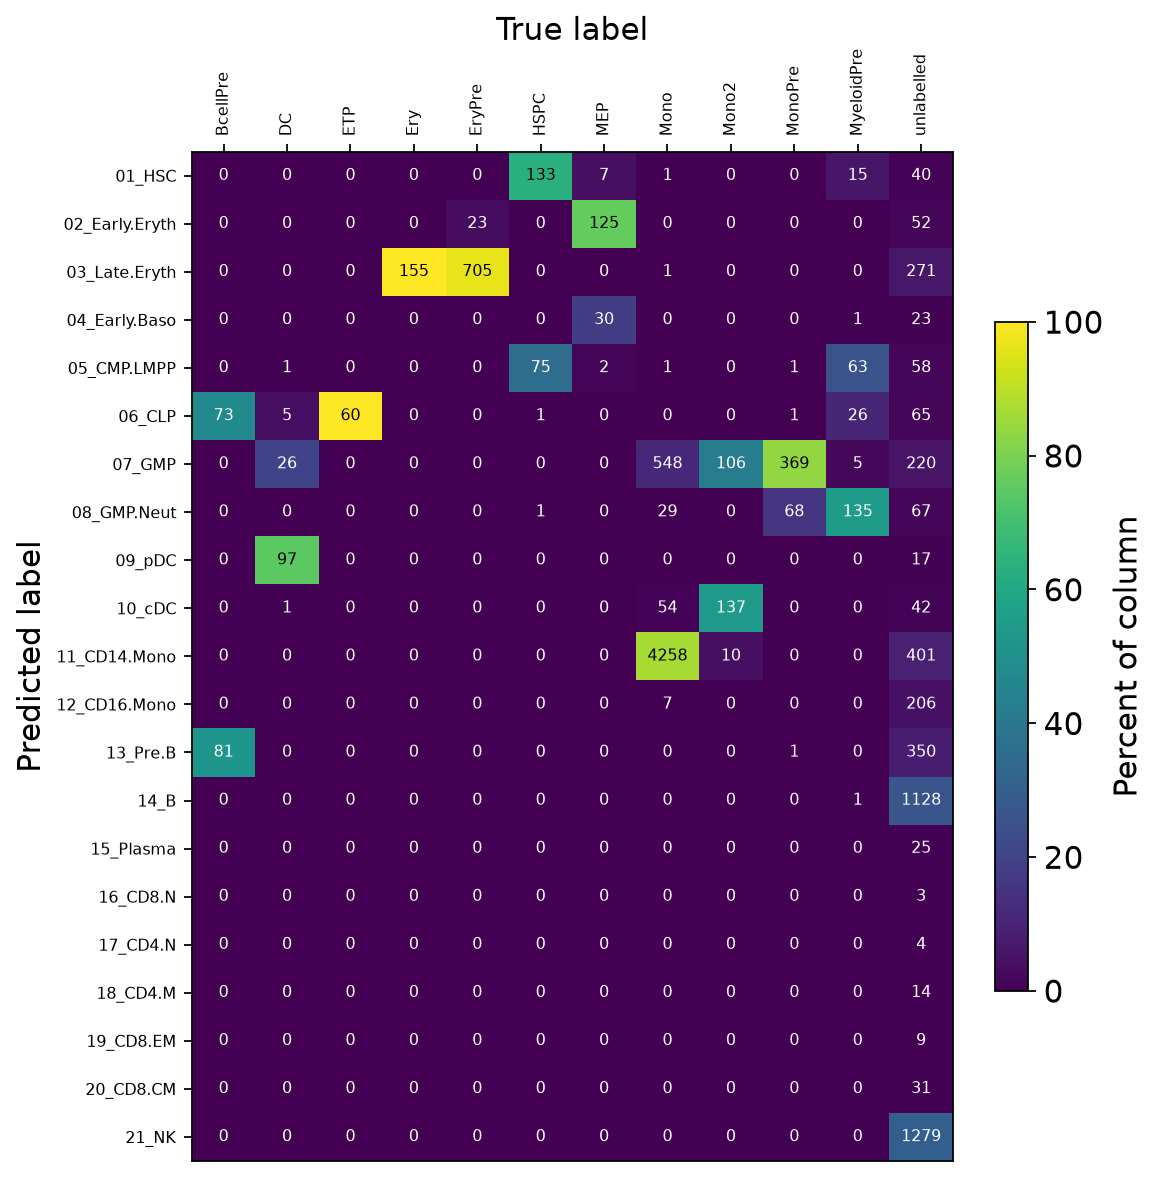

In [6]:
query = td.bm_tcelldep_full()
print(query.shape)
emb = query.copy()
sc.pp.normalize_total(emb)
sc.pp.log1p(emb)
sc.pp.highly_variable_genes(emb, n_top_genes=2000)
sc.pp.pca(emb, n_comps=30, mask_var="highly_variable")
sc.pp.neighbors(emb)
sc.tl.umap(emb, random_state=0)
query.obsm["X_umap"] = emb.obsm["X_umap"]
del emb
vm.calculate_feature_dispersion(query)
vm.select_features(query, top_n=10_000, logmean_ul=-1, logmean_ll=-8)
vga = set(vm.get_selected_features(aug))
vg = [g for g in vm.get_selected_features(query) if g in vga]
vm.viewmastR(query, aug, col, selected_features=vg)
sc.pl.umap(query, color=["viewmastR_pred", "celltype"], ncols=2)
vm.confusion_matrix(query.obs["viewmastR_pred"], query.obs["celltype"])
plt.show()

Not translated: the R article first relabels regulatory T cells by cluster and a FOXP3
marker in its own PBMC data. The held-out test above replaces that example.

## Versions

In [7]:
from importlib.metadata import version
for pkg in ("viewmastr", "scanpy", "anndata", "numpy", "scipy"):
    print(f"{pkg:10s} {version(pkg)}")

viewmastr  0.1.0
scanpy     1.12.5
anndata    0.13.4
numpy      2.5.4
scipy      1.18.1
